In [5]:
!py -m pip install fastcluster


[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: C:\Users\Ayden\AppData\Local\Programs\Python\Python313\python.exe -m pip install --upgrade pip


In [31]:
import pandas as pd
import sklearn
import numpy as np
import scipy
from sklearn.preprocessing import StandardScaler
import seaborn as sns
from matplotlib.patches import Patch

In [51]:
hierarchical_results = pd.read_csv("results/assignment3/hierarchical/cluster_labels.csv")
affinity_results = pd.read_csv("results/assignment3/affinity/cluster_results.csv")
kmeans_results = pd.read_csv("results/assignment3/kmeans/cluster_labels.csv").drop(columns=["Unnamed: 0"])
sample_groups = []
for sample in hierarchical_results["sample_id"]:
    sample_groups.append("AL" if int(sample[3:]) <= 2534782 else "RF") # True means in AL group

In [52]:
affinity_results

,Sample,10_genes_No_Preference,100_genes_No_Preference,1000_genes_No_Preference,10000_genes_No_Preference,5000_genes_None_Preference,5000_genes_-100_Preference,5000_genes_-500_Preference,5000_genes_-1000_Preference,5000_genes_-5000_Preference,5000_genes_-10000_Preference,5000_genes_-20000_Preference
0,SRR2534402,0,0,0,0,0,0,0,0,12,0,1
1,SRR2534403,0,0,0,0,0,1,0,0,12,0,1
2,SRR2534404,0,0,0,0,0,2,0,0,12,0,1
3,SRR2534405,0,0,0,0,0,3,0,0,12,0,1
4,SRR2534406,0,0,0,0,0,4,0,0,12,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...
541,SRR2535043,41,67,70,70,70,541,70,70,43,9,3
542,SRR2535044,41,67,70,70,70,542,70,70,43,9,3
543,SRR2535045,41,67,70,70,70,543,70,70,43,9,3
544,SRR2535046,41,67,70,70,70,544,70,70,43,9,3


In [53]:
# NUMBER 3 (TODO)
sorted_genes = pd.read_csv("results/assignment3/affinity/sorted_genes.csv")[:5000]
sorted_genes = sorted_genes.set_index("Gene")
sorted_genes

,SRR2534402,SRR2534403,SRR2534404,SRR2534405,SRR2534406,SRR2534407,SRR2534408,SRR2534409,SRR2534410,SRR2534411,...,SRR2535038,SRR2535039,SRR2535040,SRR2535041,SRR2535042,SRR2535043,SRR2535044,SRR2535045,SRR2535046,SRR2535047
Gene,,,,,,,,,,,,,,,,,,,,,
Lars2,18.686778,17.942373,19.279816,19.727014,20.043443,18.466178,19.021748,18.138422,90.305486,90.305486,...,11.997342,11.445452,9.899983,8.863214,9.204295,9.155986,10.286630,8.943861,9.934873,9.645423
Mir6236,40.008331,40.724974,41.262309,41.580819,40.355943,40.469911,40.285823,41.452146,80.438028,80.438028,...,35.227715,34.002301,41.843580,42.504179,41.085445,42.238744,41.326141,41.961827,41.514807,41.713337
Mup15,85.497160,84.877921,84.382044,85.497160,85.497160,84.877921,84.877921,85.497160,76.617575,78.605492,...,80.001721,79.282446,98.170073,98.170073,97.362222,98.170073,97.362222,97.362222,98.170073,99.066884
Mup17,74.490667,75.350819,75.050092,75.050092,74.749365,75.050092,75.350819,74.749365,71.182024,70.924421,...,77.984974,76.954759,93.417512,94.029779,93.417512,94.029779,93.417512,94.029779,94.029779,93.417512
Grip2,57.645500,47.460108,29.807702,28.382645,39.775930,29.680578,33.569053,24.718278,52.866789,45.741073,...,59.079150,67.010969,58.625124,55.672795,39.645982,43.867946,46.822504,42.238744,45.647330,53.196817
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
Hapln1,1.784237,1.790912,2.071189,2.075389,1.789864,1.789864,2.061379,4.002090,2.942350,2.653743,...,4.736202,4.337819,2.875941,2.885617,2.789633,3.733101,4.555945,3.326265,4.657968,2.987286
Phf12,5.182819,7.218366,6.969324,6.381997,7.323834,6.750636,6.294357,4.647401,4.926013,6.079760,...,5.090784,7.342575,6.496087,7.354428,5.296818,5.992903,7.090605,6.220473,6.383911,6.726279
Galk1,10.687181,9.877920,9.000387,10.149036,9.462959,9.083058,9.474694,9.628402,8.972047,8.524392,...,11.459452,10.847172,9.701756,9.285437,8.244301,8.765846,8.109147,9.178822,10.001307,8.571497


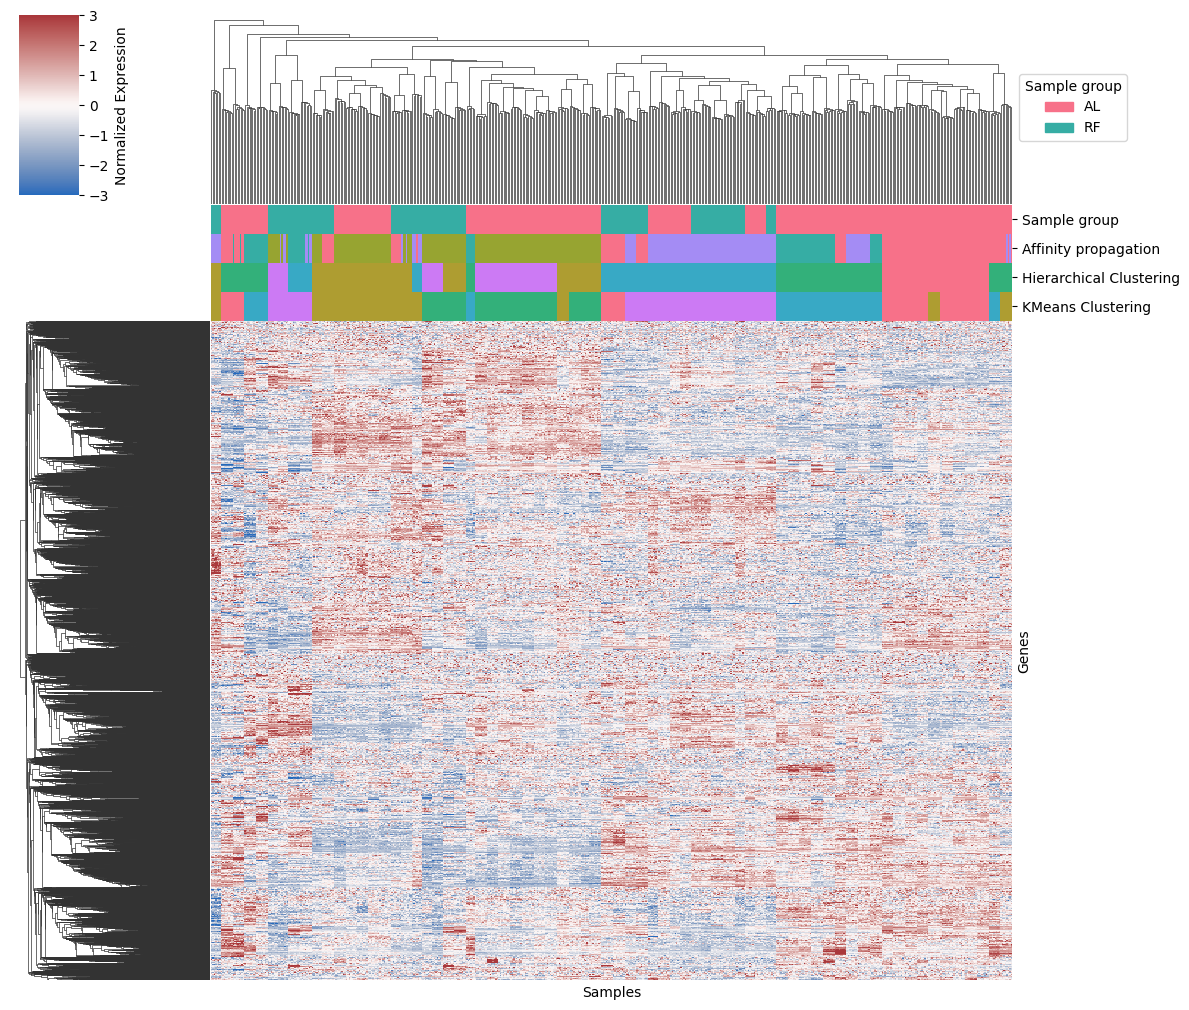

In [62]:
annotations = pd.DataFrame({"Sample group": sample_groups,
                            "Affinity propagation": list(affinity_results["5000_genes_-20000_Preference"]),
                            "Hierarchical Clustering": list(hierarchical_results["hierarchical_g5000_k5"]),
                            "KMeans Clustering": list(kmeans_results["kmeans_g5000_k5"])}, index=sorted_genes.columns)

col_colors = pd.DataFrame(index=sorted_genes.columns)
luts = {}
for name in annotations:
    cats = annotations[name].unique()
    luts[name] = dict(zip(cats, sns.color_palette("husl", len(cats))))
    col_colors[name] = annotations[name].map(luts[name])

g = sns.clustermap(sorted_genes, z_score=0, cmap="vlag", center=0, vmin=-3, vmax=3, col_colors=col_colors,
                   xticklabels=False, yticklabels=False, figsize=(12,10), cbar_kws={"label": "Normalized Expression"})

g.ax_heatmap.set_xlabel("Samples")
g.ax_heatmap.set_ylabel("Genes")

handles = [Patch(color=c, label=l) for l, c in luts["Sample group"].items()]
g.ax_col_dendrogram.legend(handles=handles, title="Sample group", loc="center left", bbox_to_anchor=(1, 0.5))

g.savefig("results/assignment3/heatmap.png")

In [43]:
# NUMBER 4

methods = []
p_values = []

for col in affinity_results.columns:
    if col == "Sample":
        continue
    stat, p_val, _, _ = scipy.stats.chi2_contingency(pd.crosstab(affinity_results[col], sample_groups))
    p_values.append(p_val)
    col = "affinity_"+col
    methods.append(col)

for col in hierarchical_results.columns:
    if col == "sample_id":
        continue
    stat, p_val, _, _ = scipy.stats.chi2_contingency(pd.crosstab(hierarchical_results[col], sample_groups))
    p_values.append(p_val)
    methods.append(col)

for col in kmeans_results.columns:
    if col == "sample_id":
        continue
    stat, p_val, _, _ = scipy.stats.chi2_contingency(pd.crosstab(kmeans_results[col], sample_groups))
    p_values.append(p_val)
    methods.append(col)


p_values = scipy.stats.false_discovery_control(p_values)

significance_table = {"Method": methods, "p_values": p_values}

pd.DataFrame(significance_table).set_index("Method")

,p_values
Method,
affinity_10_genes_No_Preference,4.559957e-74
affinity_100_genes_No_Preference,7.878704e-75
affinity_1000_genes_No_Preference,4.559957e-74
affinity_10000_genes_No_Preference,4.559957e-74
affinity_5000_genes_None_Preference,4.559957e-74
affinity_5000_genes_-100_Preference,5.098694e-01
affinity_5000_genes_-500_Preference,4.559957e-74
affinity_5000_genes_-1000_Preference,4.559957e-74
affinity_5000_genes_-5000_Preference,7.878704e-75
